# AcademiQ - Notebook 03: Regression Modeling

This notebook evaluates three regression architectures to predict student examination scores:
1. **Simple Linear Regression** (baseline using `Hours_Studied`)
2. **Multiple Linear Regression** (all numerical and categorical predictors)
3. **Polynomial Regression** (degree-2 polynomial features on numerical predictors)

All workflows employ strict `Pipeline` encapsulation to ensure zero data leakage during evaluation and 5-fold cross-validation.


In [1]:
import os
from pathlib import Path

def get_project_root():
    current = Path.cwd().resolve()
    for candidate in [current, current.parent, current.parent.parent]:
        if (candidate / "data" / "raw").exists() or (candidate / "requirements.txt").exists():
            return candidate
    return current

PROJECT_ROOT = get_project_root()
os.chdir(PROJECT_ROOT)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    files = None

from sklearn.model_selection import cross_validate
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    PolynomialFeatures
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib

pd.set_option("display.max_columns", None)
print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:
import os
from pathlib import Path
import pandas as pd

processed_dir = PROJECT_ROOT / "data" / "processed"
train_file = processed_dir / "AcademiQ_Train_Cleaned.csv"
test_file = processed_dir / "AcademiQ_Test_Cleaned.csv"

if not train_file.exists() and os.path.exists("/content/AcademiQ_Train_Cleaned.csv"):
    train_file = Path("/content/AcademiQ_Train_Cleaned.csv")
    test_file = Path("/content/AcademiQ_Test_Cleaned.csv")

train_df = pd.read_csv(train_file)
test_df = pd.read_csv(test_file)

print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)
display(train_df.head())


Training dataset: (5285, 20)
Testing dataset: (1322, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,27,79,Low,High,Yes,8,63,High,Yes,2,Low,Medium,Public,Negative,5,No,College,Moderate,Female,69
1,16,86,High,Medium,Yes,7,94,Medium,Yes,2,Low,High,Public,Neutral,3,No,High School,Moderate,Female,69
2,22,87,Low,Medium,No,8,83,Low,Yes,1,Low,Medium,Public,Neutral,1,No,College,Far,Male,66
3,18,100,High,Medium,Yes,10,86,Medium,Yes,1,Medium,Medium,Public,Neutral,3,No,High School,Near,Male,72
4,35,78,High,Low,Yes,10,99,Medium,Yes,1,Low,Medium,Private,Positive,2,No,High School,Near,Male,72


In [3]:
target = "Exam_Score"

X_train = train_df.drop(columns=[target])
y_train = train_df[target]

X_test = test_df.drop(columns=[target])
y_test = test_df[target]

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (5285, 19)
Testing features: (1322, 19)
Training target: (5285,)
Testing target: (1322,)


In [4]:
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']

Categorical features:
['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


C:\Users\mansi\AppData\Local\Temp\ipykernel_9968\1124402278.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [5]:
numeric_pipeline = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [6]:
simple_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            ["Hours_Studied"]
        )
    ]
)

simple_linear_model = Pipeline(
    steps=[
        ("preprocessor", simple_preprocessor),
        ("regressor", LinearRegression())
    ]
)

print("Simple Linear Regression model created.")

Simple Linear Regression model created.


In [7]:
multiple_linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)

print("Multiple Linear Regression model created.")

Multiple Linear Regression model created.


In [8]:
polynomial_numeric_pipeline = Pipeline(
    steps=[
        (
            "polynomial",
            PolynomialFeatures(
                degree=2,
                include_bias=False
            )
        ),
        ("scaler_after_poly", StandardScaler())
    ]
)

polynomial_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            polynomial_numeric_pipeline,
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

polynomial_model = Pipeline(
    steps=[
        ("preprocessor", polynomial_preprocessor),
        ("regressor", LinearRegression())
    ]
)

print("Polynomial Regression model created.")

Polynomial Regression model created.


In [9]:
models = {
    "Simple Linear Regression": simple_linear_model,
    "Multiple Linear Regression": multiple_linear_model,
    "Polynomial Regression": polynomial_model
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully.")

Simple Linear Regression trained successfully.
Multiple Linear Regression trained successfully.
Polynomial Regression trained successfully.


### Regression Performance Evaluation
We evaluate models on the held-out test set using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and $R^2$ Score.


In [10]:
results = []

predictions = {}

for name, model in models.items():

    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

regression_results = pd.DataFrame(results)

display(
    regression_results.round(4)
)

,Model,MAE,MSE,RMSE,R2 Score
0,Simple Linear Regression,2.4476,10.8560,3.2948,0.2320
1,Multiple Linear Regression,0.4498,3.2520,1.8033,0.7699
2,Polynomial Regression,0.4660,3.2736,1.8093,0.7684


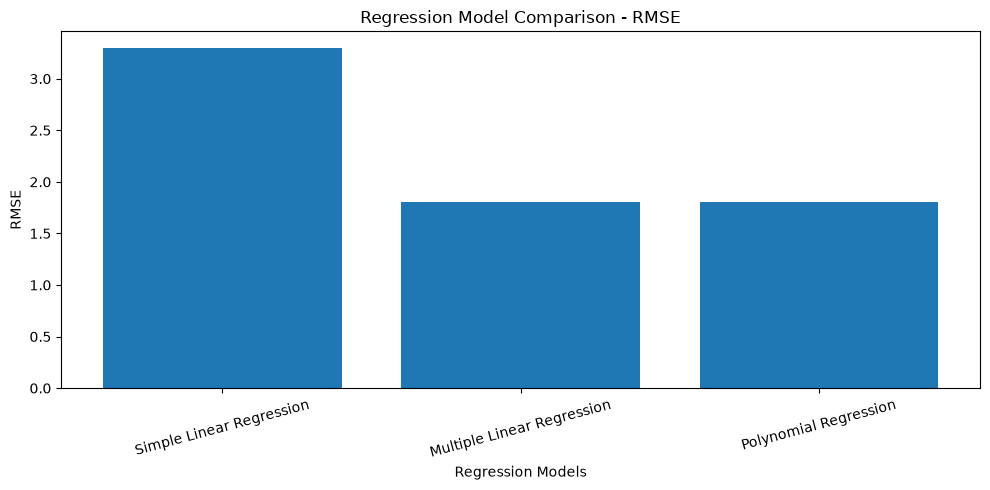

In [11]:
plt.figure(figsize=(10, 5))

plt.bar(
    regression_results["Model"],
    regression_results["RMSE"]
)

plt.title("Regression Model Comparison - RMSE")
plt.xlabel("Regression Models")
plt.ylabel("RMSE")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

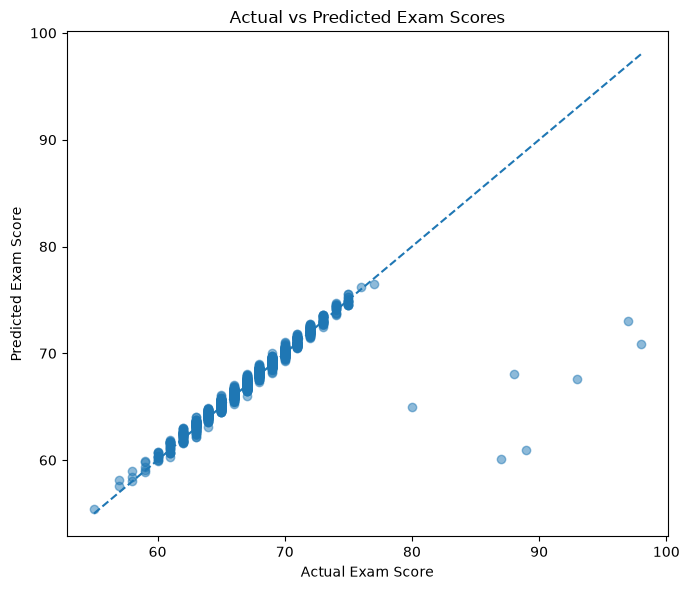

In [12]:
actual = y_test.values
predicted = predictions["Multiple Linear Regression"]

plt.figure(figsize=(7, 6))

plt.scatter(actual, predicted, alpha=0.5)

minimum = min(actual.min(), predicted.min())
maximum = max(actual.max(), predicted.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.title("Actual vs Predicted Exam Scores")
plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.tight_layout()
plt.show()

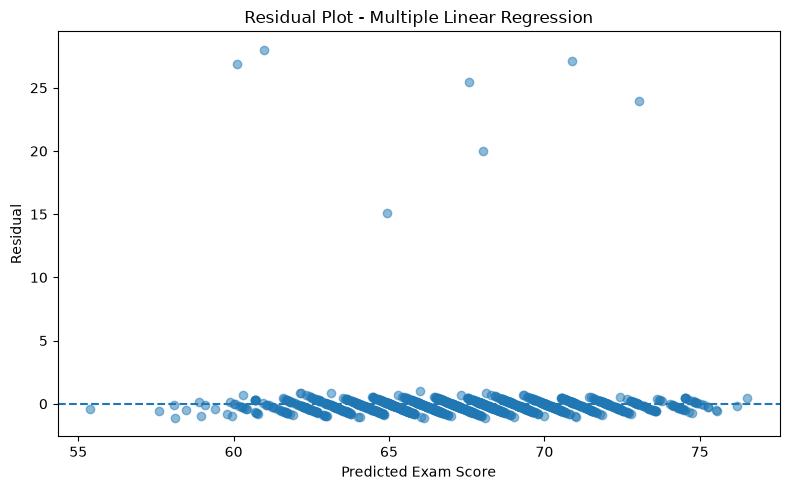

In [13]:
residuals = actual - predicted

plt.figure(figsize=(8, 5))

plt.scatter(predicted, residuals, alpha=0.5)
plt.axhline(y=0, linestyle="--")

plt.title("Residual Plot - Multiple Linear Regression")
plt.xlabel("Predicted Exam Score")
plt.ylabel("Residual")
plt.tight_layout()
plt.show()

In [14]:
cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=5,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "MSE": "neg_mean_squared_error",
            "R2": "r2"
        }
    )

    cv_results.append({
        "Model": name,
        "Mean MAE": -scores["test_MAE"].mean(),
        "Mean MSE": -scores["test_MSE"].mean(),
        "Mean RMSE": np.sqrt(-scores["test_MSE"]).mean(),
        "Mean R2": scores["test_R2"].mean()
    })

cv_comparison = pd.DataFrame(cv_results)

display(cv_comparison.round(4))

,Model,Mean MAE,Mean MSE,Mean RMSE,Mean R2
0,Simple Linear Regression,2.5205,12.4552,3.5179,0.1924
1,Multiple Linear Regression,0.5067,4.3919,2.0497,0.7237
2,Polynomial Regression,0.5289,4.4083,2.0540,0.7226


In [15]:
import os
results_reg_dir = PROJECT_ROOT / "results" / "regression"
results_reg_dir.mkdir(parents=True, exist_ok=True)

regression_results.to_csv(results_reg_dir / "AcademiQ_Regression_Test_Results.csv", index=False)
cv_comparison.to_csv(results_reg_dir / "AcademiQ_Regression_CV_Results.csv", index=False)

print("Regression result files saved successfully to results/regression/.")


Regression result files saved successfully to results/regression/.


In [16]:
models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    simple_linear_model,
    models_dir / "AcademiQ_Simple_Linear_Regression.pkl"
)

joblib.dump(
    multiple_linear_model,
    models_dir / "AcademiQ_Multiple_Linear_Regression.pkl"
)

joblib.dump(
    polynomial_model,
    models_dir / "AcademiQ_Polynomial_Regression.pkl"
)

print("Regression models successfully saved to models/:")
print("1. models/AcademiQ_Simple_Linear_Regression.pkl")
print("2. models/AcademiQ_Multiple_Linear_Regression.pkl")
print("3. models/AcademiQ_Polynomial_Regression.pkl")


Regression models successfully saved to models/:
1. models/AcademiQ_Simple_Linear_Regression.pkl
2. models/AcademiQ_Multiple_Linear_Regression.pkl
3. models/AcademiQ_Polynomial_Regression.pkl


In [17]:
best_model_row = regression_results.loc[
    regression_results["RMSE"].idxmin()
]

print("Best Regression Model:")
print(best_model_row["Model"])

print("\nTest RMSE:", round(best_model_row["RMSE"], 4))
print("Test MAE:", round(best_model_row["MAE"], 4))
print("Test R2:", round(best_model_row["R2 Score"], 4))

Best Regression Model:
Multiple Linear Regression

Test RMSE: 1.8033
Test MAE: 0.4498
Test R2: 0.7699


In [18]:
if IN_COLAB and files is not None:
    try:
        files.download(str(PROJECT_ROOT / "results" / "regression" / "AcademiQ_Regression_Test_Results.csv"))
    except Exception as e:
        print(f"Colab download skipped: {e}")
else:
    print("Results saved in results/regression/.")


Results saved in results/regression/.


In [19]:
if IN_COLAB and files is not None:
    try:
        files.download(str(PROJECT_ROOT / "results" / "regression" / "AcademiQ_Regression_CV_Results.csv"))
    except Exception as e:
        print(f"Colab download skipped: {e}")
else:
    print("CV results saved in results/regression/.")


CV results saved in results/regression/.
